# 02 · Preprocessing, imbalance handling and model comparison

Plan:
1. Stratified train/test split, and why a time-based split would be even more realistic
2. Scaling `Time` and `Amount`
3. Class weights vs SMOTE, compared with cross-validation, plus a demonstration of **data leakage** when SMOTE is done wrong
4. Train four models (Logistic Regression, Random Forest, XGBoost, Isolation Forest) and compare them on the test set
5. Save test-set predictions for the Streamlit app

In [1]:
import sys
sys.path.append("..")

import time
import joblib
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from imblearn.over_sampling import SMOTE
from sklearn.metrics import roc_curve
from sklearn.model_selection import StratifiedKFold, cross_validate

from fraudguard.config import FIGURES_DIR, MODELS_DIR, RANDOM_STATE
from fraudguard.data import load_data
from fraudguard.evaluate import compute_metrics, default_predictions, fraud_scores
from fraudguard.models import (build_pipeline, isolation_forest, logistic_regression,
                               random_forest, xgboost)
from fraudguard.plotting import (MODEL_COLORS, MUTED_COLOR, apply_style,
                                 plot_confusion_matrix, plot_pr_curves)
from fraudguard.preprocessing import make_scaler, split_data

apply_style()
pd.set_option("display.precision", 3)

## 1 · Train/test split

We hold out 20% of the data as a **test set** that is used only once, at the very end, to estimate how
the model would perform on new transactions. The split is **stratified**, so both parts keep the 0.17% fraud rate.

In [2]:
df = load_data()
X_train, X_test, y_train, y_test = split_data(df)

print(f"Train: {len(X_train):,} rows, {y_train.sum()} frauds ({y_train.mean():.3%})")
print(f"Test:  {len(X_test):,} rows, {y_test.sum()} frauds ({y_test.mean():.3%})")

Train: 227,845 rows, 394 frauds (0.173%)
Test:  56,962 rows, 98 frauds (0.172%)


> **Why a time-based split would be even more realistic.** In production a model is trained on the past and
> used on the future. A random split lets the model train on transactions from hour 40 and be tested on hour 10,
> so it "sees the future". Fraud patterns also drift over time, and fraudsters adapt. A time-based split
> (train on the first ~38 hours, test on the last ~10) would give a more honest and usually slightly lower
> score. We use a stratified random split because the dataset only covers **2 days** and has only 492 frauds,
> so a time split would leave very few frauds to test on and the results would be very noisy. With months of
> data, a time-based split would be the right choice.

## 2 · Scaling

`V1`–`V28` are PCA outputs that are already centred and on a similar scale. `Time` (0 to 172,792) and `Amount`
(0 to 25,691) are not. Logistic Regression is sensitive to feature scale; tree models are not, but scaling
doesn't hurt them. We use a `RobustScaler` (median/IQR), which is less affected by the few very large amounts.

The scaler is **fitted on training data only**. Here we fit it manually to show the effect; in the models it
sits inside a Pipeline, which guarantees the same thing automatically.

In [3]:
scaler = make_scaler().fit(X_train)
before = X_train[["Time", "Amount"]].describe().loc[["mean", "50%", "std", "max"]]
after = scaler.transform(X_train)[["Time", "Amount"]].describe().loc[["mean", "50%", "std", "max"]]
pd.concat({"before scaling": before, "after scaling": after}, axis=1).round(2)

before scaling           after scaling        
               Time    Amount          Time  Amount
mean       94885.09     88.18          0.12    0.92
50%        84805.00     22.00          0.00    0.00
std        47488.42    250.72          0.56    3.49
max       172792.00  25691.16          1.03  357.26

## 3 · Handling the imbalance: class weights vs SMOTE

With 577 normal transactions for every fraud, a model can get a tiny loss by mostly ignoring fraud.
Two standard fixes:

| Approach | How it works | Trade-off |
|---|---|---|
| **Class weights** | Each fraud counts ~577x more in the loss function. Data unchanged. | Cheap, no fake data |
| **SMOTE** | Creates *synthetic* frauds by interpolating between a real fraud and its nearest fraud neighbours, until classes are balanced. | Twice the training data, synthetic points may not be realistic |

### SMOTE and data leakage

SMOTE must only ever be applied to **training data**. If you oversample *before* splitting or cross-validating,
synthetic frauds created from a fraud in the training fold end up in the validation fold. They are near-copies of
training points, so the model "recognises" them and the scores look much better than reality. That's **data leakage**.

The fix: put SMOTE **inside** an imbalanced-learn `Pipeline`. During `cross_validate`, the pipeline is re-fitted on
each training fold, so SMOTE only sees that fold, and resampling steps are automatically **skipped** when
predicting on the validation fold. Let's prove it matters:

In [4]:
cv = StratifiedKFold(n_splits=5, shuffle=True, random_state=RANDOM_STATE)

# WRONG: oversample the whole training set first, then cross-validate on the oversampled data.
X_scaled = make_scaler().fit_transform(X_train)
X_resampled, y_resampled = SMOTE(random_state=RANDOM_STATE).fit_resample(X_scaled, y_train)
wrong = cross_validate(xgboost(), X_resampled, y_resampled, cv=cv, scoring=["recall", "precision"])

# RIGHT: SMOTE inside the pipeline, so it only runs on each training fold.
right = cross_validate(build_pipeline(xgboost(), use_smote=True), X_train, y_train, cv=cv,
                       scoring=["recall", "precision"])

pd.DataFrame({
    "SMOTE before CV (leaky)": {"recall": wrong["test_recall"].mean(), "precision": wrong["test_precision"].mean()},
    "SMOTE inside pipeline (correct)": {"recall": right["test_recall"].mean(), "precision": right["test_precision"].mean()},
}).T

,recall,precision
SMOTE before CV (leaky),1.000,0.998
SMOTE inside pipeline (correct),0.845,0.499


The leaky version reports near-perfect recall and precision. That's an illusion: its validation folds are
half synthetic frauds that are near-copies of training points, and it is evaluated on a 50/50 class mix that will
never happen in reality. The correct version shows what we can really expect. **Same model, same data, very
different conclusion.**

### Comparing strategies with cross-validation

We compare no rebalancing, class weights and SMOTE for Logistic Regression and XGBoost using 5-fold stratified
cross-validation **on the training set only** (the test set stays untouched).
The main metric is **PR-AUC** (average precision): it measures how well the model *ranks* frauds above normal
transactions, regardless of the decision threshold.
(Random Forest is left out here only to keep the runtime reasonable: it takes about a minute per fit, and SMOTE
doubles the data.)

In [5]:
normal_per_fraud = (y_train == 0).sum() / (y_train == 1).sum()

candidates = {
    ("Logistic Regression", "none"): build_pipeline(logistic_regression()),
    ("Logistic Regression", "class weights"): build_pipeline(logistic_regression(class_weight="balanced")),
    ("Logistic Regression", "SMOTE"): build_pipeline(logistic_regression(), use_smote=True),
    ("XGBoost", "none"): build_pipeline(xgboost()),
    ("XGBoost", "class weights"): build_pipeline(xgboost(scale_pos_weight=normal_per_fraud)),
    ("XGBoost", "SMOTE"): build_pipeline(xgboost(), use_smote=True),
}

rows = {}
for key, pipeline in candidates.items():
    start = time.time()
    scores = cross_validate(pipeline, X_train, y_train, cv=cv,
                            scoring=["average_precision", "precision", "recall", "f1"])
    rows[key] = {
        "PR-AUC": scores["test_average_precision"].mean(),
        "PR-AUC std": scores["test_average_precision"].std(),
        "precision @0.5": scores["test_precision"].mean(),
        "recall @0.5": scores["test_recall"].mean(),
        "F1 @0.5": scores["test_f1"].mean(),
        "seconds": time.time() - start,
    }

cv_results = pd.DataFrame(rows).T
cv_results.index.names = ["model", "imbalance strategy"]
cv_results

PR-AUC  PR-AUC std  precision @0.5  \
model               imbalance strategy                                       
Logistic Regression none                 0.762       0.043           0.884   
                    class weights        0.757       0.051           0.063   
                    SMOTE                0.753       0.048           0.060   
XGBoost             none                 0.856       0.019           0.940   
                    class weights        0.847       0.018           0.877   
                    SMOTE                0.839       0.021           0.499   

                                        recall @0.5  F1 @0.5  seconds  
model               imbalance strategy                                 
Logistic Regression none                      0.642    0.743    2.709  
                    class weights             0.914    0.118    4.619  
                    SMOTE                     0.919    0.113    7.711  
XGBoost             none                      0.787    0.856   23.601  
                    class weights             0.827    0.850   23.762  
                    SMOTE                     0.845    0.625   40.998

**What this shows (an important, slightly surprising result):**
- **PR-AUC barely changes** between strategies (differences are about the size of the fold-to-fold std).
  Rebalancing does not make the model better at *ranking* frauds above normal transactions.
- What rebalancing does change is the **probability scale**. Class weights and SMOTE push predicted fraud
  probabilities up, so at the default 0.5 threshold they catch more frauds (higher recall) but raise many more false
  alarms (Logistic Regression's precision collapses from ~0.88 to ~0.06).
- In other words, rebalancing mostly acts like **moving the threshold**. Since in notebook 03 we choose the threshold
  explicitly with a cost model, we don't need it, and an un-reweighted model has an extra advantage: its
  probabilities stay **calibrated** (a score of 0.3 really means roughly a 30% chance of fraud), which is useful
  in the app.

**Decision:** train the final models **without rebalancing**, handle the imbalance with stratification,
the right metrics and a tuned threshold. On another dataset rebalancing may help, so it's always worth testing
like this.

## 4 · Training and comparing the four models

- **Logistic Regression:** linear baseline, fast and interpretable.
- **Random Forest:** many decision trees trained on random subsets, averaged.
- **XGBoost:** gradient-boosted trees: each new tree corrects the errors of the previous ones. Our main model.
- **Isolation Forest:** *unsupervised*: trained **without labels**. It flags transactions that are easy to isolate
  from the rest. Useful when you have no labelled fraud at all; here it shows how much labels are worth.
  (We do tell it the expected fraud rate via `contamination`, which uses a little label knowledge.)

In [6]:
models = {
    "Logistic Regression": build_pipeline(logistic_regression()),
    "Random Forest": build_pipeline(random_forest()),
    "XGBoost": build_pipeline(xgboost()),
    "Isolation Forest": build_pipeline(isolation_forest(contamination=y_train.mean())),
}

for name, model in models.items():
    start = time.time()
    model.fit(X_train, y_train)  # Isolation Forest ignores y
    print(f"{name:20s} trained in {time.time() - start:5.1f} s")

Logistic Regression  trained in   0.6 s


Random Forest        trained in  39.9 s


XGBoost              trained in   5.6 s


Isolation Forest     trained in   3.1 s


In [7]:
scores = pd.DataFrame({name: fraud_scores(m, X_test) for name, m in models.items()}, index=X_test.index)
preds = pd.DataFrame({name: default_predictions(m, X_test) for name, m in models.items()}, index=X_test.index)

metrics = pd.DataFrame({name: compute_metrics(y_test, preds[name], scores[name]) for name in models}).T

# The "accuracy trap" baseline: always predict "not fraud".
always_normal = np.zeros(len(y_test), dtype=int)
metrics.loc["Always 'not fraud'"] = compute_metrics(y_test, always_normal, always_normal)

metrics = metrics[["precision", "recall", "f1", "roc_auc", "pr_auc", "accuracy"]]
metrics.style.format("{:.3f}").highlight_max(subset=["precision", "recall", "f1", "roc_auc", "pr_auc"],
                                             color="#cde2fb")

,precision,recall,f1,roc_auc,pr_auc,accuracy
Logistic Regression,0.829,0.643,0.724,0.957,0.739,0.999
Random Forest,0.940,0.806,0.868,0.952,0.867,1.000
XGBoost,0.930,0.816,0.870,0.980,0.867,1.000
Isolation Forest,0.246,0.286,0.264,0.956,0.156,0.997
Always 'not fraud',0.000,0.000,0.000,0.500,0.002,0.998


Metrics use each model's default decision rule (probability ≥ 0.5; Isolation Forest: its `contamination` cut-off).

- **Accuracy is useless here.** "Always not fraud" scores 0.998 accuracy, only 0.002 below the best models, while catching nothing.
- **Precision** = of the transactions we flagged, how many were really fraud? (cost of false alarms)
- **Recall** = of all real frauds, how many did we catch? (cost of missed fraud)
- **ROC-AUC** is above 0.95 for *every* model, even Isolation Forest, whose PR-AUC is only 0.16. ROC-AUC is inflated by
  the huge number of easy true negatives. **PR-AUC** focuses on the fraud class and shows the real gap between models.

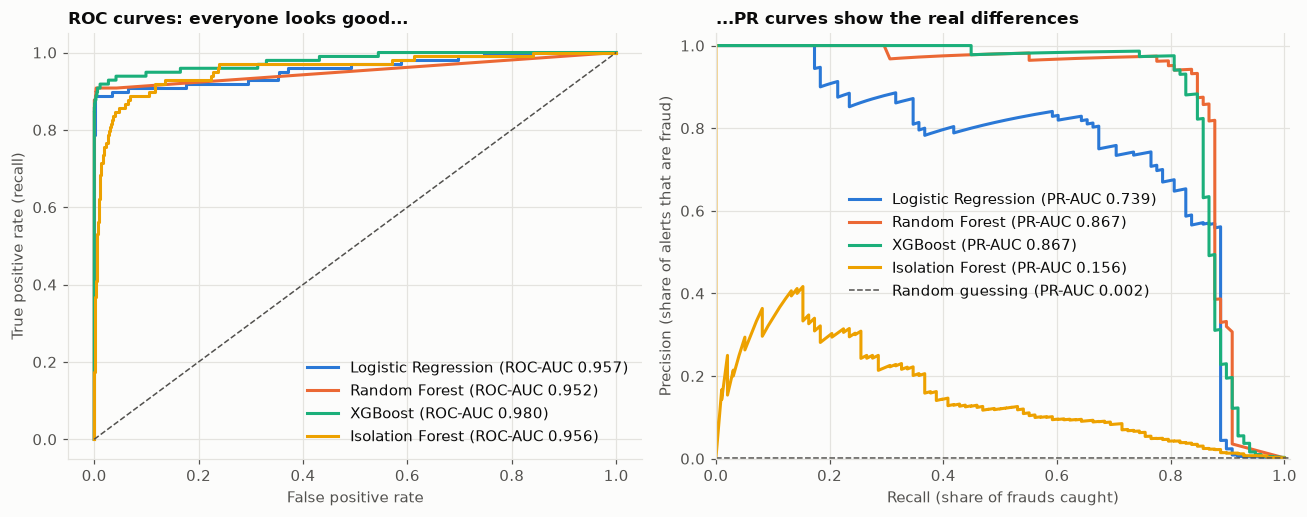

In [8]:
fig, (ax_roc, ax_pr) = plt.subplots(1, 2, figsize=(12, 4.8))

for color, name in zip(MODEL_COLORS, models):
    fpr, tpr, _ = roc_curve(y_test, scores[name])
    ax_roc.plot(fpr, tpr, color=color, label=f"{name} (ROC-AUC {metrics.loc[name, 'roc_auc']:.3f})")
ax_roc.plot([0, 1], [0, 1], color=MUTED_COLOR, linestyle="--", linewidth=1)
ax_roc.set_xlabel("False positive rate")
ax_roc.set_ylabel("True positive rate (recall)")
ax_roc.set_title("ROC curves: everyone looks good...")
ax_roc.legend(loc="lower right")

plot_pr_curves(ax_pr, y_test, {name: scores[name] for name in models})
ax_pr.set_title("...PR curves show the real differences")
fig.tight_layout()
fig.savefig(FIGURES_DIR / "roc_vs_pr_curves.png")
plt.show()

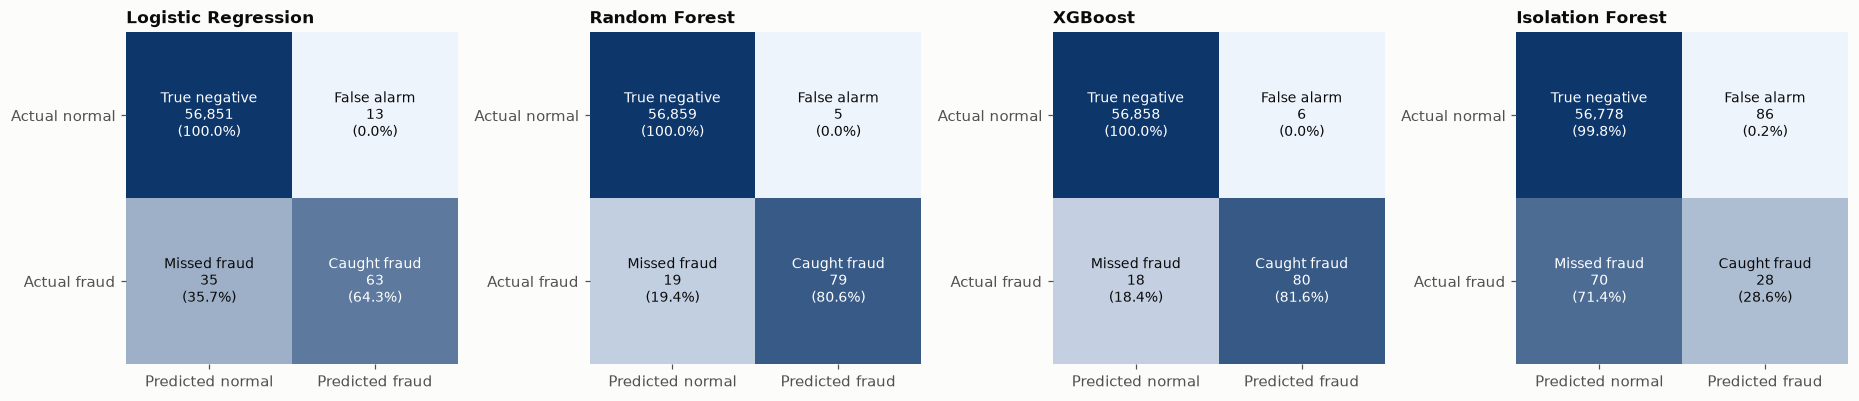

In [9]:
fig, axes = plt.subplots(1, 4, figsize=(17, 3.8))
for ax, name in zip(axes, models):
    plot_confusion_matrix(ax, y_test, preds[name], title=name)
fig.tight_layout()
fig.savefig(FIGURES_DIR / "confusion_matrices.png")
plt.show()

**Observations:**
- **XGBoost and Random Forest tie on PR-AUC (0.867)** and both clearly beat Logistic Regression (0.739). The tree
  models capture non-linear patterns (like the night-time effect) that a linear model can't.
- **We pick XGBoost as the main model**: same PR-AUC, best ROC-AUC (0.980), ~8x faster to train (5 s vs 42 s) and a
  much smaller saved file, which matters for GitHub and Streamlit Cloud.
- At the default 0.5 threshold XGBoost **catches 80 of 98 frauds (81.6%) with only 6 false alarms** out of ~57,000
  normal transactions. Is 0.5 the right threshold, though? That's a business question, answered in notebook 03.
- **Isolation Forest** (no labels) catches only 28 of 98 frauds, with 86 false alarms. Its PR-AUC of 0.156 is still
  ~90x better than random (0.0017), but labels are clearly worth a lot. Unsupervised detection is still useful in
  practice for *new* fraud patterns that have no labels yet.
- Caveat: the test set has only **98 frauds**, so one fraud is about 1 percentage point of recall. A difference
  of 1-2 caught frauds between RF and XGBoost is noise, not a real difference.

In [10]:
# Save test-set scores for the Streamlit app (small: ~57k rows x a few columns, compressed).
results = pd.DataFrame({"Class": y_test, "Amount": X_test["Amount"]})
for name in models:
    results[f"score_{name}"] = scores[name].astype("float32")
    results[f"pred_{name}"] = preds[name].astype("int8")

MODELS_DIR.mkdir(exist_ok=True)
joblib.dump({"results": results, "metrics": metrics}, MODELS_DIR / "test_predictions.joblib", compress=3)
print("Saved", MODELS_DIR / "test_predictions.joblib")

Saved D:\Projects\fraud-detection\models\test_predictions.joblib
